In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

Load dataset

In [2]:
df = pd.read_csv("food-texture.csv")

print("Original dataset:")
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())

Original dataset:
  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143

Missing values:
Unnamed: 0    0
Oil           0
Density       0
Crispy        0
Fracture      0
Hardness      0
dtype: int64


Remove ID column and duplicate rows

In [ ]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.drop_duplicates()

Select numerical features

In [22]:
import numpy as np
from scipy.stats import skew, kurtosis, shapiro

In [23]:
numeric_data = df.select_dtypes(include=np.number)

In [24]:
print(numeric_data.head())

    Oil  Density  Crispy  Fracture  Hardness
0  16.5     2955      10        23        97
1  17.7     2660      14         9       139
2  16.2     2870      12        17       143
3  16.7     2920      10        31        95
4  16.3     2975      11        26       143


Descriptive statistics

In [25]:
stats = numeric_data.describe().T
stats["median"] = numeric_data.median()
stats["variance"] = numeric_data.var()
stats["skewness"] = numeric_data.apply(
    lambda x: skew(x, bias=False)
)

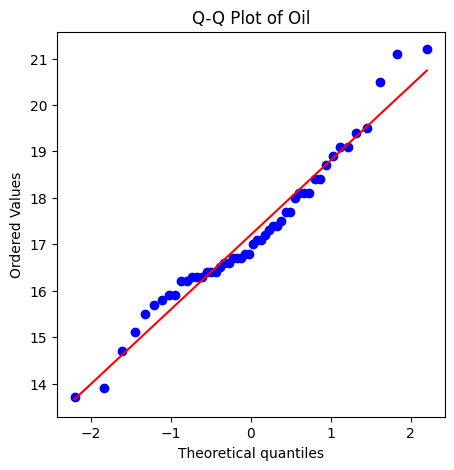

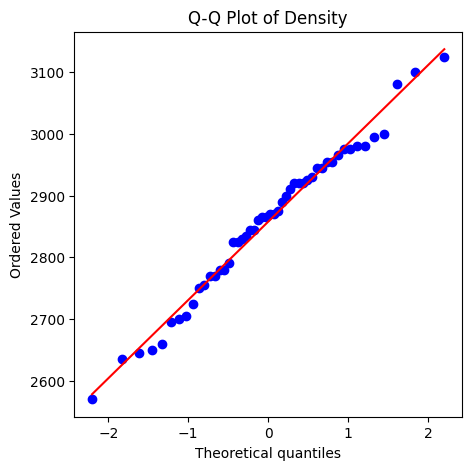

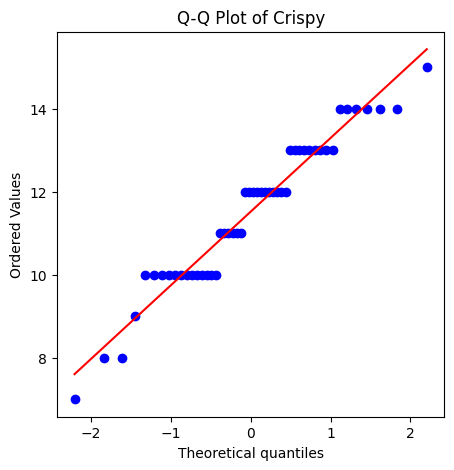

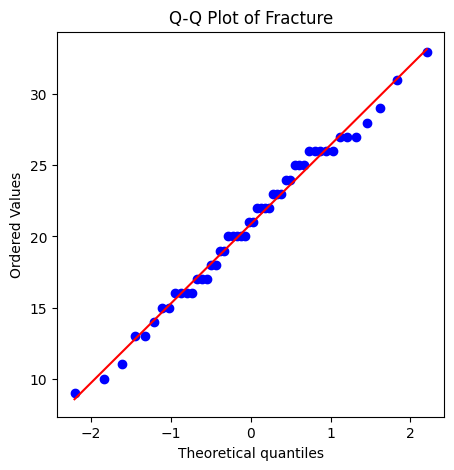

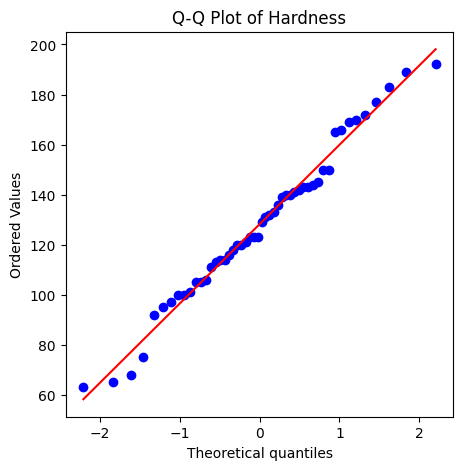

In [26]:
import scipy.stats as stats
import matplotlib.pyplot as plt

for column in numeric_data.columns:
    plt.figure(figsize=(5, 5))
    stats.probplot(
        numeric_data[column].dropna(),
        dist="norm",
        plot=plt
    )
    plt.title(f"Q-Q Plot of {column}")
    plt.show()

Data type: int64
Number of unique values: 9
Unique values:
[7, 8, 9, 10, 11, 12, 13, 14, 15]

Frequency distribution:
Crispy
7      1
8      2
9      1
10    13
11     6
12    11
13     9
14     6
15     1
Name: count, dtype: int64


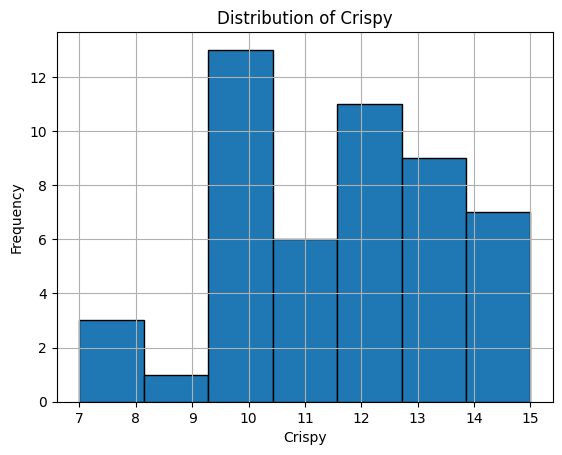

In [27]:
print("Data type:", numeric_data["Crispy"].dtype)

print("Number of unique values:",
      numeric_data["Crispy"].nunique())

print("Unique values:")
print(sorted(numeric_data["Crispy"].dropna().unique()))

print("\nFrequency distribution:")
print(numeric_data["Crispy"].value_counts().sort_index())

# Visualise Crispy separately
numeric_data["Crispy"].hist(
    bins="auto",
    edgecolor="black"
)
plt.title("Distribution of Crispy")
plt.xlabel("Crispy")
plt.ylabel("Frequency")
plt.show()


Probability Distribution of Oil
   Interval_Start  Interval_End  Frequency  Probability
0         13.7000       14.6375          2         0.04
1         14.6375       15.5750          3         0.06
2         15.5750       16.5125         13         0.26
3         16.5125       17.4500         14         0.28
4         17.4500       18.3875          7         0.14
5         18.3875       19.3250          6         0.12
6         19.3250       20.2625          2         0.04
7         20.2625       21.2000          3         0.06


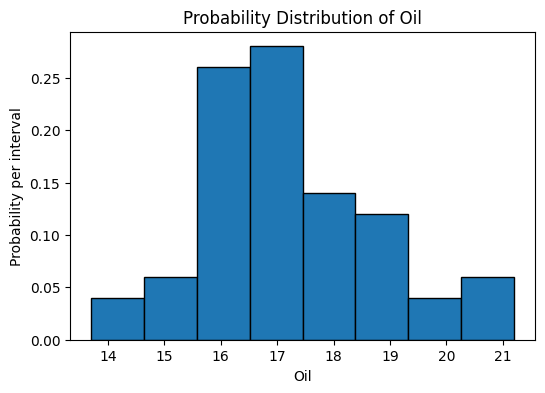


Probability Distribution of Density
   Interval_Start  Interval_End  Frequency  Probability
0       2570.0000     2649.2857          3         0.06
1       2649.2857     2728.5714          6         0.12
2       2728.5714     2807.8571          7         0.14
3       2807.8571     2887.1429         12         0.24
4       2887.1429     2966.4286         13         0.26
5       2966.4286     3045.7143          6         0.12
6       3045.7143     3125.0000          3         0.06


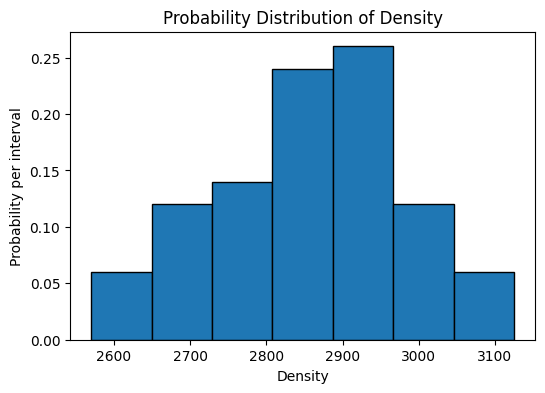


Probability Distribution of Crispy
   Interval_Start  Interval_End  Frequency  Probability
0          7.0000        8.1429          3         0.06
1          8.1429        9.2857          1         0.02
2          9.2857       10.4286         13         0.26
3         10.4286       11.5714          6         0.12
4         11.5714       12.7143         11         0.22
5         12.7143       13.8571          9         0.18
6         13.8571       15.0000          7         0.14


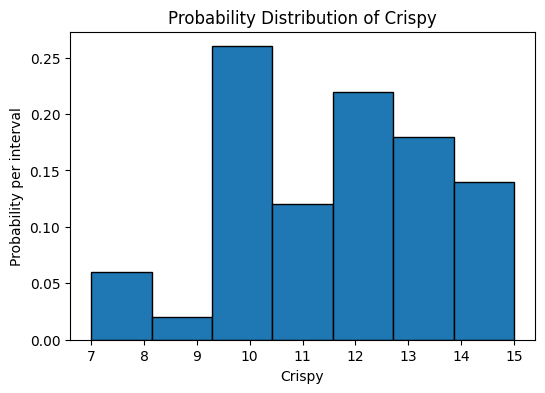


Probability Distribution of Fracture
   Interval_Start  Interval_End  Frequency  Probability
0          9.0000       12.4286          3         0.06
1         12.4286       15.8571          5         0.10
2         15.8571       19.2857         11         0.22
3         19.2857       22.7143         11         0.22
4         22.7143       26.1429         13         0.26
5         26.1429       29.5714          5         0.10
6         29.5714       33.0000          2         0.04


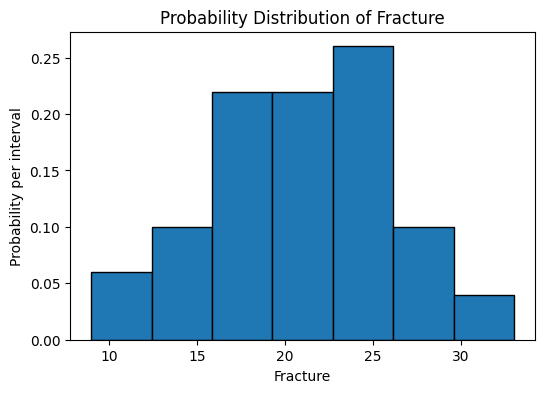


Probability Distribution of Hardness
   Interval_Start  Interval_End  Frequency  Probability
0         63.0000       81.4286          4         0.08
1         81.4286       99.8571          3         0.06
2         99.8571      118.2857         12         0.24
3        118.2857      136.7143         11         0.22
4        136.7143      155.1429         11         0.22
5        155.1429      173.5714          5         0.10
6        173.5714      192.0000          4         0.08


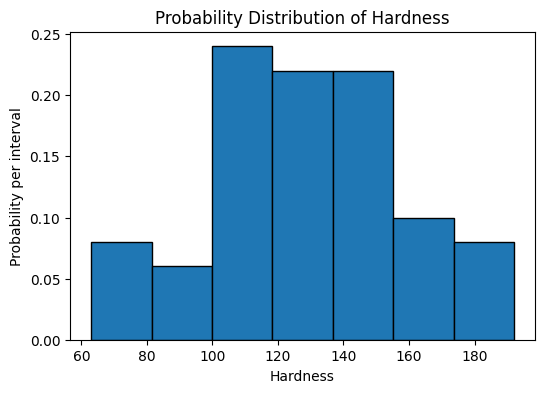

In [29]:
# Probability distribution for every feature
for column in numeric_data.columns:
    values = numeric_data[column].dropna()

    # Count observations in each interval
    frequency, bins = np.histogram(values, bins="auto")

    # Calculate probability for each interval
    probability = frequency / frequency.sum()

    # Display probability table
    distribution = pd.DataFrame({
        "Interval_Start": bins[:-1],
        "Interval_End": bins[1:],
        "Frequency": frequency,
        "Probability": probability
    })

    print(f"\nProbability Distribution of {column}")
    print(distribution.round(4))

    # Plot probability distribution
    plt.figure(figsize=(6, 4))
    plt.bar(
        bins[:-1],
        probability,
        width=np.diff(bins),
        align="edge",
        edgecolor="black"
    )
    plt.title(f"Probability Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Probability per interval")
    plt.show()


Separate input features and target

In [4]:
X = df[["Oil", "Density", "Crispy", "Fracture"]]
y = df["Hardness"]

Split into training and testing data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

Preprocess numerical features

In [6]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), X.columns.tolist())
])

Create Linear Regression pipeline

In [7]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

Train the model

In [8]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Oil', 'Density', 'Crispy',
                                                   'Fracture'])])),
                ('regression', LinearRegression())])

Predict on test data

In [9]:
y_pred = model.predict(X_test)

Evaluate model

In [10]:
print("\nModel Evaluation")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))


Model Evaluation
MAE: 13.567290222542784
RMSE: 18.85008752485196
R2 Score: 0.37065922831282394


Compare actual and predicted values

In [11]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.round(2)
})

print("\nActual vs Predicted:")
print(results)


Actual vs Predicted:
   Actual  Predicted
0     169     166.77
1     105     127.50
2     106     150.31
3     120     123.22
4     142     145.28
5     116     115.53
6     100     123.47
7     150     141.91
8      92     110.83
9     140     149.26


Crispy as output

In [12]:
# Separate input and output
X = df[["Oil", "Density", "Fracture", "Hardness"]]
y = df["Crispy"]

In [14]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
# Imputation and feature scaling
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), X.columns.tolist())
])

In [16]:
# Create and train model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Oil', 'Density', 'Fracture',
                                                   'Hardness'])])),
                ('regressor', LinearRegression())])

In [17]:
# Predict output
y_pred = model.predict(X_test)

In [18]:
# Evaluate model
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.41778314464263994
RMSE: 0.4755323678528962
R2 Score: 0.9352060077719822


In [19]:
# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Crispy": y_test.values,
    "Predicted Crispy": y_pred.round(2)
})
print(results)

   Actual Crispy  Predicted Crispy
0             12             11.40
1             10              9.75
2             10              9.65
3             11             10.60
4             12             12.25
5             13             13.53
6             10              9.94
7             12             12.91
8              7              7.54
9             14             14.27


   Value  Frequency  Probability
0      7          1         0.02
1      8          2         0.04
2      9          1         0.02
3     10         13         0.26
4     11          6         0.12
5     12         11         0.22
6     13          9         0.18
7     14          6         0.12
8     15          1         0.02


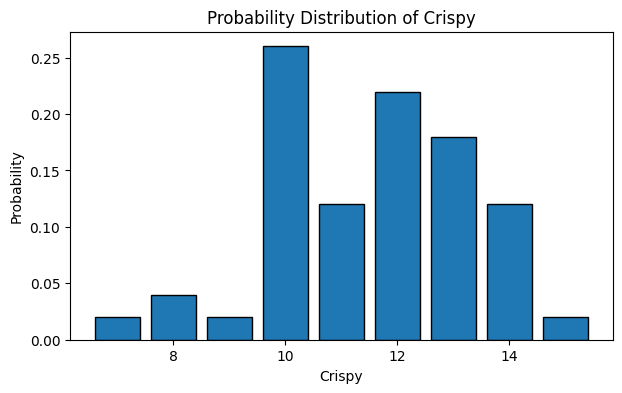

In [30]:

counts = numeric_data["Crispy"].value_counts().sort_index()

crispy_probability = pd.DataFrame({
    "Value": counts.index,
    "Frequency": counts.values,
    "Probability": counts.values / counts.sum()
})

print(crispy_probability)

plt.figure(figsize=(7, 4))
plt.bar(
    crispy_probability["Value"],
    crispy_probability["Probability"],
    edgecolor="black"
)
plt.title("Probability Distribution of Crispy")
plt.xlabel("Crispy")
plt.ylabel("Probability")
plt.show()


In [32]:
import seaborn as sns

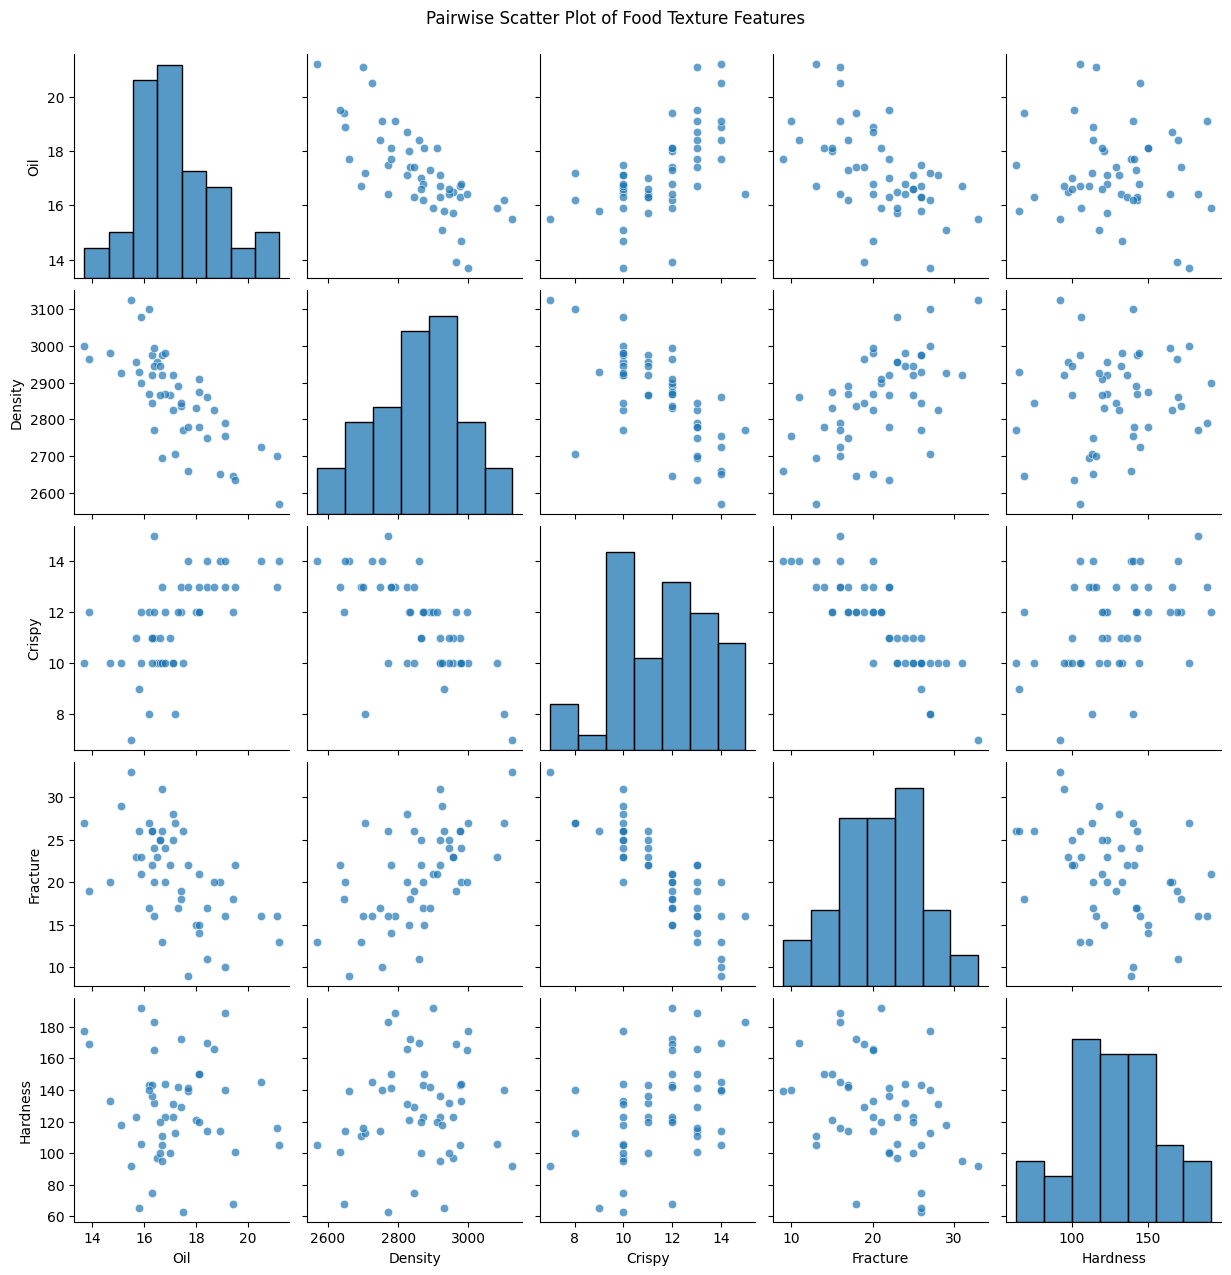

In [33]:
# Create pairwise scatter plot
sns.pairplot(
    numeric_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.7}
)

plt.suptitle("Pairwise Scatter Plot of Food Texture Features",
             y=1.02)
plt.show()


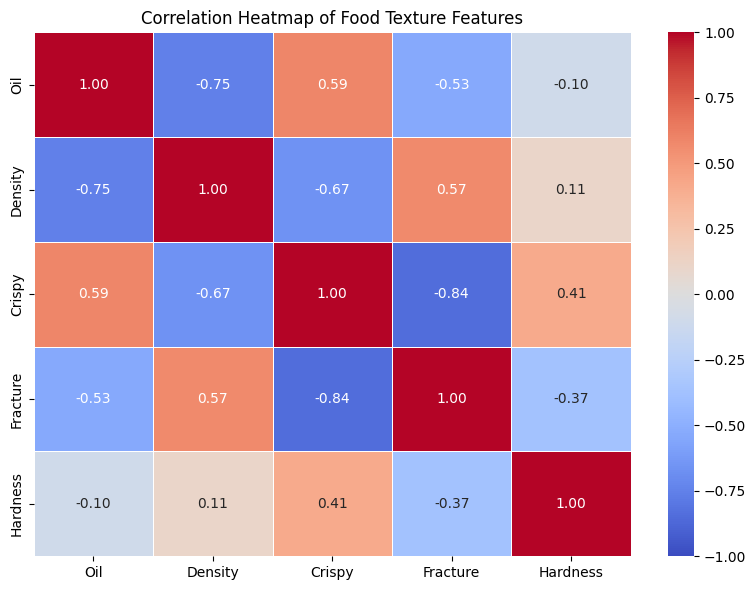

In [34]:
# Step 4: Calculate the correlation matrix
correlation_matrix = numeric_data.corr()

# Step 5: Create the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Food Texture Features")
plt.tight_layout()
plt.show()

In [36]:
# Correlation of each input feature with Crispy
correlations = df.corr(numeric_only=True)["Crispy"].drop("Crispy")

print("Correlation with Crispy:")
print(correlations.sort_values(key=abs, ascending=False))

# Select the two strongest correlations
best_two = correlations.abs().nlargest(2).index.tolist()

print("\nBest two features:", best_two)


Correlation with Crispy:
Fracture   -0.843965
Density    -0.670946
Oil         0.593086
Hardness    0.411093
Name: Crispy, dtype: float64

Best two features: ['Fracture', 'Density']


In [39]:
from sklearn.pipeline import make_pipeline

In [40]:

# Select the best two features
X = df[best_two]
y = df["Crispy"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Selected features:", best_two)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R²:", round(r2_score(y_test, y_pred), 3))

Selected features: ['Fracture', 'Density']
MAE: 0.41
RMSE: 0.477
R²: 0.935


compare original and best two     write down the interpretation

upload this in github

In [41]:
results = pd.DataFrame({
    "Actual Crispy": y_test.values,
    "Predicted Crispy": y_pred
})

print(results.round(2))

   Actual Crispy  Predicted Crispy
0             12             11.61
1             10              9.98
2             10             10.29
3             11             10.60
4             12             12.34
5             13             13.24
6             10             10.31
7             12             12.85
8              7              7.85
9             14             14.41
